<a href="https://colab.research.google.com/github/psh135230-design/BioAI_KU_2026/blob/main/%EB%B0%94%EC%9D%B4%EC%98%A4%EC%9D%B8%EA%B3%B5%EC%A7%80%EB%8A%A5%EC%A4%91%EA%B0%84(10/12).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
file_path = "/content/drive/MyDrive/바이오 인공지능 /GSE154763_MYE_count.h5"

In [9]:
import h5py

file_path = "/content/drive/MyDrive/바이오 인공지능 /GSE154763_MYE_count.h5"

with h5py.File(file_path, "r") as f:
    print("Top-level keys:")
    print(list(f.keys()))

Top-level keys:
['unknown']


In [11]:
import h5py

file_path = "/content/drive/MyDrive/바이오 인공지능 /GSE154763_MYE_count.h5"

with h5py.File(file_path, "r") as f:
    print(list(f["unknown"].keys()))

# `barcodes`는 단일 세포 식별용 고유 DNA 염기서열 배열.
# `gene_names`와 `genes`는 각각 일반 유전자 심볼과 고유 식별자(Ensembl ID).
# `data`는 0이 아닌 발현량 값만 모은 1차원 배열, `indices`는 해당 값이 몇 번째 유전자(행)인지 나타내는 위치 정보
#`indptr`은 새로운 세포(열) 데이터가 시작되는 기준점 포인터
# `shape`는 압축 해제 시 생성될 전체 행렬의 원래 크기(유전자 수 × 세포 수)를 의미함.

['barcodes', 'data', 'gene_names', 'genes', 'indices', 'indptr', 'shape']


In [12]:
!pip install scanpy

import h5py
import scanpy as sc
import pandas as pd
from scipy.sparse import csc_matrix

# H5 파일에서 데이터 읽기
with h5py.File(file_path, "r") as f:
    g = f["unknown"]

    # CSC (Compressed Sparse Column) 형식으로 행렬 복원
    # indptr 크기가 열 크기(shape[1]) + 1과 맞으므로 csc_matrix를 사용해야 합니다.
    X = csc_matrix(
        (g["data"][:], g["indices"][:], g["indptr"][:]),
        shape=g["shape"][:]
    )

    # 유전자(Genes) 및 바코드(Cells) 정보 로드
    obs_names = [b.decode("utf-8") for b in g["barcodes"][:]]
    var_names = [g_name.decode("utf-8") for g_name in g["gene_names"][:]]

    # AnnData를 생성하기 위해 행과 열의 크기에 맞게 데이터 정리
    # X의 shape가 (genes, cells)인 경우 전치(Transpose)가 필요합니다.
    if X.shape == (len(var_names), len(obs_names)):
        X = X.T

    obs = pd.DataFrame(index=obs_names)
    var = pd.DataFrame(index=var_names)
    if "genes" in g:
        var["gene_ids"] = [gene.decode("utf-8") for gene in g["genes"][:]]

# AnnData 객체 생성
adata = sc.AnnData(X=X, obs=obs, var=var)

# 정보 출력
print(adata)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 28.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 74.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 55.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.7 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take in

In [ ]:
adata.obs.head()

""
AAACCTGAGCGTAATA-19
AAACGGGAGATCACGG-19
AAACGGGCAAGCGCTC-19
AAAGATGAGCCACGCT-19
AAAGCAAAGTCGTTTG-19


In [14]:
adata.write_h5ad("/content/drive/MyDrive/바이오인공지능 /GSE154763_MYE_count.h5")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 28.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 76.8 MB/s eta 0:00:00


/tmp/ipykernel_904/2173441357.py:25: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata)


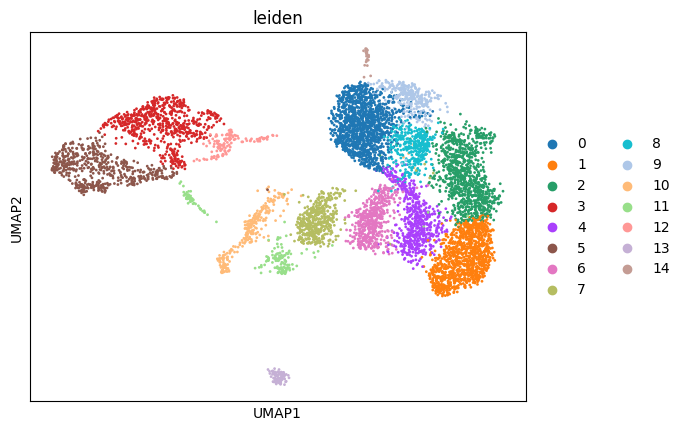

In [15]:
!pip install leidenalg

import scanpy as sc

# QC
sc.pp.calculate_qc_metrics(adata, inplace=True)

# Normalization
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

# Highly Variable Genes
sc.pp.highly_variable_genes(adata)

# PCA
sc.tl.pca(adata)

# Neighbors
sc.pp.neighbors(adata)

# UMAP
sc.tl.umap(adata)

# Clustering
sc.tl.leiden(adata)

# 시각화
sc.pl.umap(adata, color="leiden")

### Highly Variable Genes (HVG) 및 PCA 분석

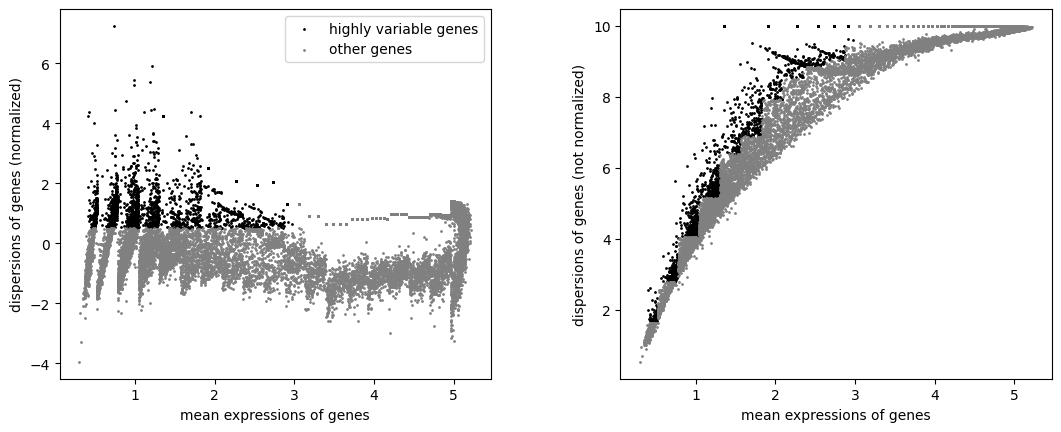

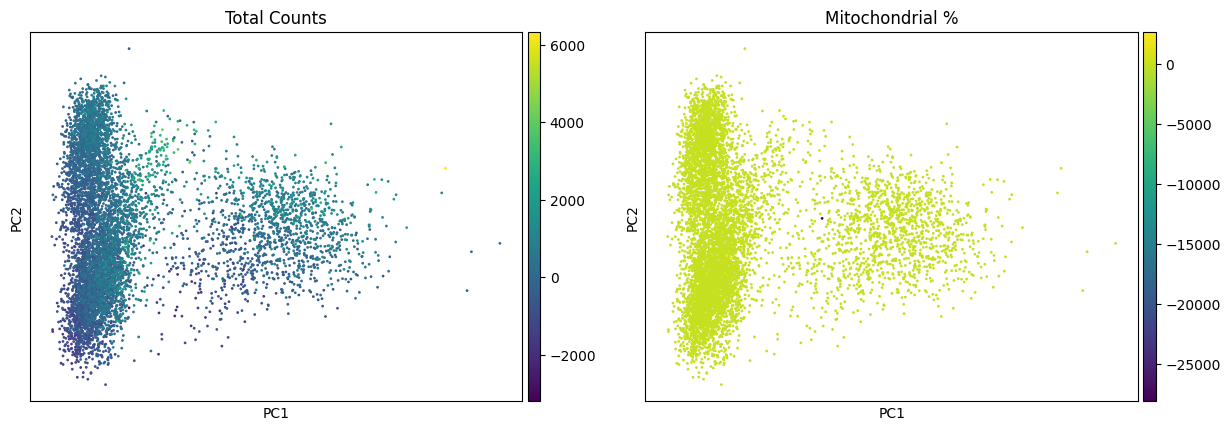

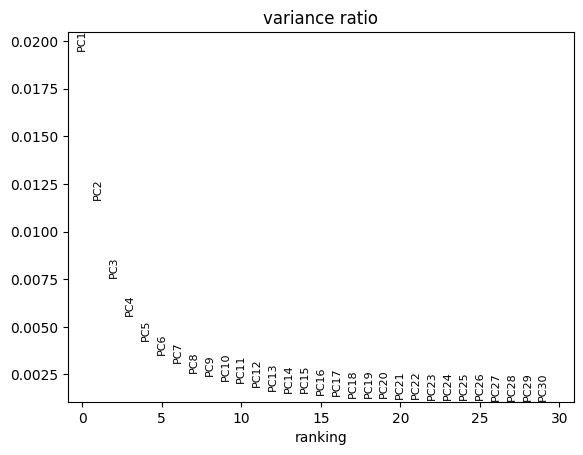

,주성분 (PC),설명 분산 비율 (%),누적 설명 분산 비율 (%)
0,PC1,1.95,1.95
1,PC2,1.17,3.11
2,PC3,0.76,3.87
3,PC4,0.56,4.43
4,PC5,0.43,4.85
5,PC6,0.35,5.21
6,PC7,0.31,5.52
7,PC8,0.26,5.78
8,PC9,0.24,6.02
9,PC10,0.22,6.24


In [23]:
import scanpy as sc
import numpy as np


# 1. Highly Variable Genes (HVG) 계산 및 플롯
# (주의: 이미 이전에 normalize와 log1p가 완료된 adata 객체를 사용합니다)
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
sc.pl.highly_variable_genes(adata)

# `min_mean=0.0125`: 노이즈 및 결측치(Dropout)가 많은 극저발현 유전자 배제.
# `max_mean=3`: 데이터 분산을 왜곡하는 하우스키핑 유전자 등 극고발현 유전자 제외.
# `min_disp=0.5`: 세포 군집(Cluster) 구별에 유의미한 변동성(Dispersion)이 큰 유전자만 선별.

#논문에서는 HVG 상위 2000개를 고름
#위 값은 튜토리얼 기본 값

# 2. PCA 수행 전 데이터 스케일링 (정규화)
# 회귀 분석이나 스케일링 전 원본 데이터를 저장해두기 위해 raw 속성을 설정합니다.
adata.raw = adata
sc.pp.scale(adata, max_value=10)

# 3. PCA 실행
sc.tl.pca(adata, n_comps=30, svd_solver="arpack")

# mitochondria QC
# 1. 미토콘드리아 유전자 (Human: 'MT-', Mouse: 'mt-' 또는 'GRCm39_mt-') 지정
adata.var["mt"] = adata.var_names.str.startswith("MT-")  # 필요 시 'mt-' 로 변경

# 2. QC 지표 계산 (adata.obs에 'total_counts', 'pct_counts_mt' 등이 자동 추가됨)
sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True
)

# 4. PCA 결과 시각화
# 주성분 1, 2 기준 개별 세포 분포
sc.pl.pca(
    adata,
    color=["total_counts", "pct_counts_mt"],
    ncols=2,
    title=["Total Counts", "Mitochondrial %"],
)

# 주성분들의 기여도 (Elbow Plot)
ax = sc.pl.pca_variance_ratio(adata, n_pcs=30)

# 5. PC 1~30 설명 분산 비율 (%) 데이터프레임 생성 및 출력
variance_ratio = adata.uns["pca"]["variance_ratio"][:30]
pcs = [f"PC{i+1}" for i in range(len(variance_ratio))]
explained_pct = variance_ratio * 100
cumulative_pct = np.cumsum(explained_pct)

pca_summary_df = pd.DataFrame(
    {
        "주성분 (PC)": pcs,
        "설명 분산 비율 (%)": np.round(explained_pct, 2),
        "누적 설명 분산 비율 (%)": np.round(cumulative_pct, 2),
    }
)

# 표 출력
pd.set_option("display.max_rows", 30)
display(pca_summary_df)

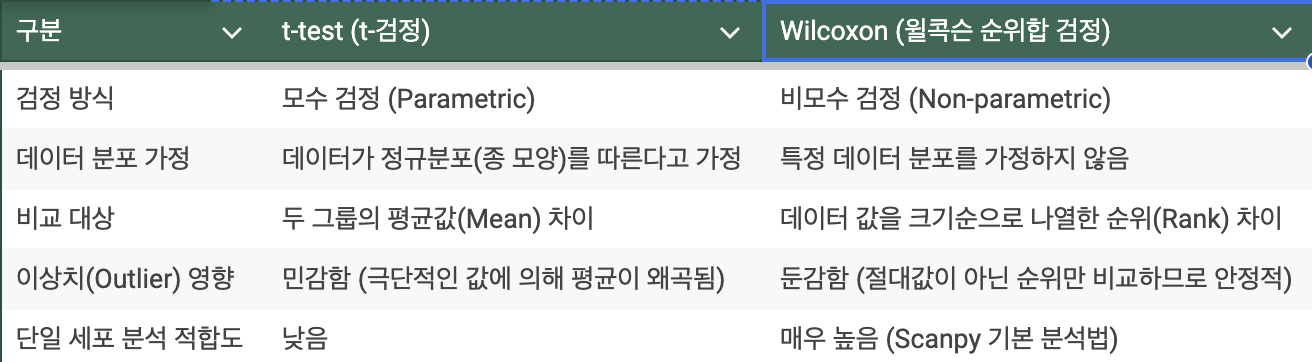![image.png]()

### 1. 클러스터별 마커 유전자 탐색 (Marker Gene Identification)

/usr/local/lib/python3.13/dist-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/dist-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/dist-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/dist-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/dist-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/dist-packages/scanpy/tools/_rank_genes_groups.py:633: 

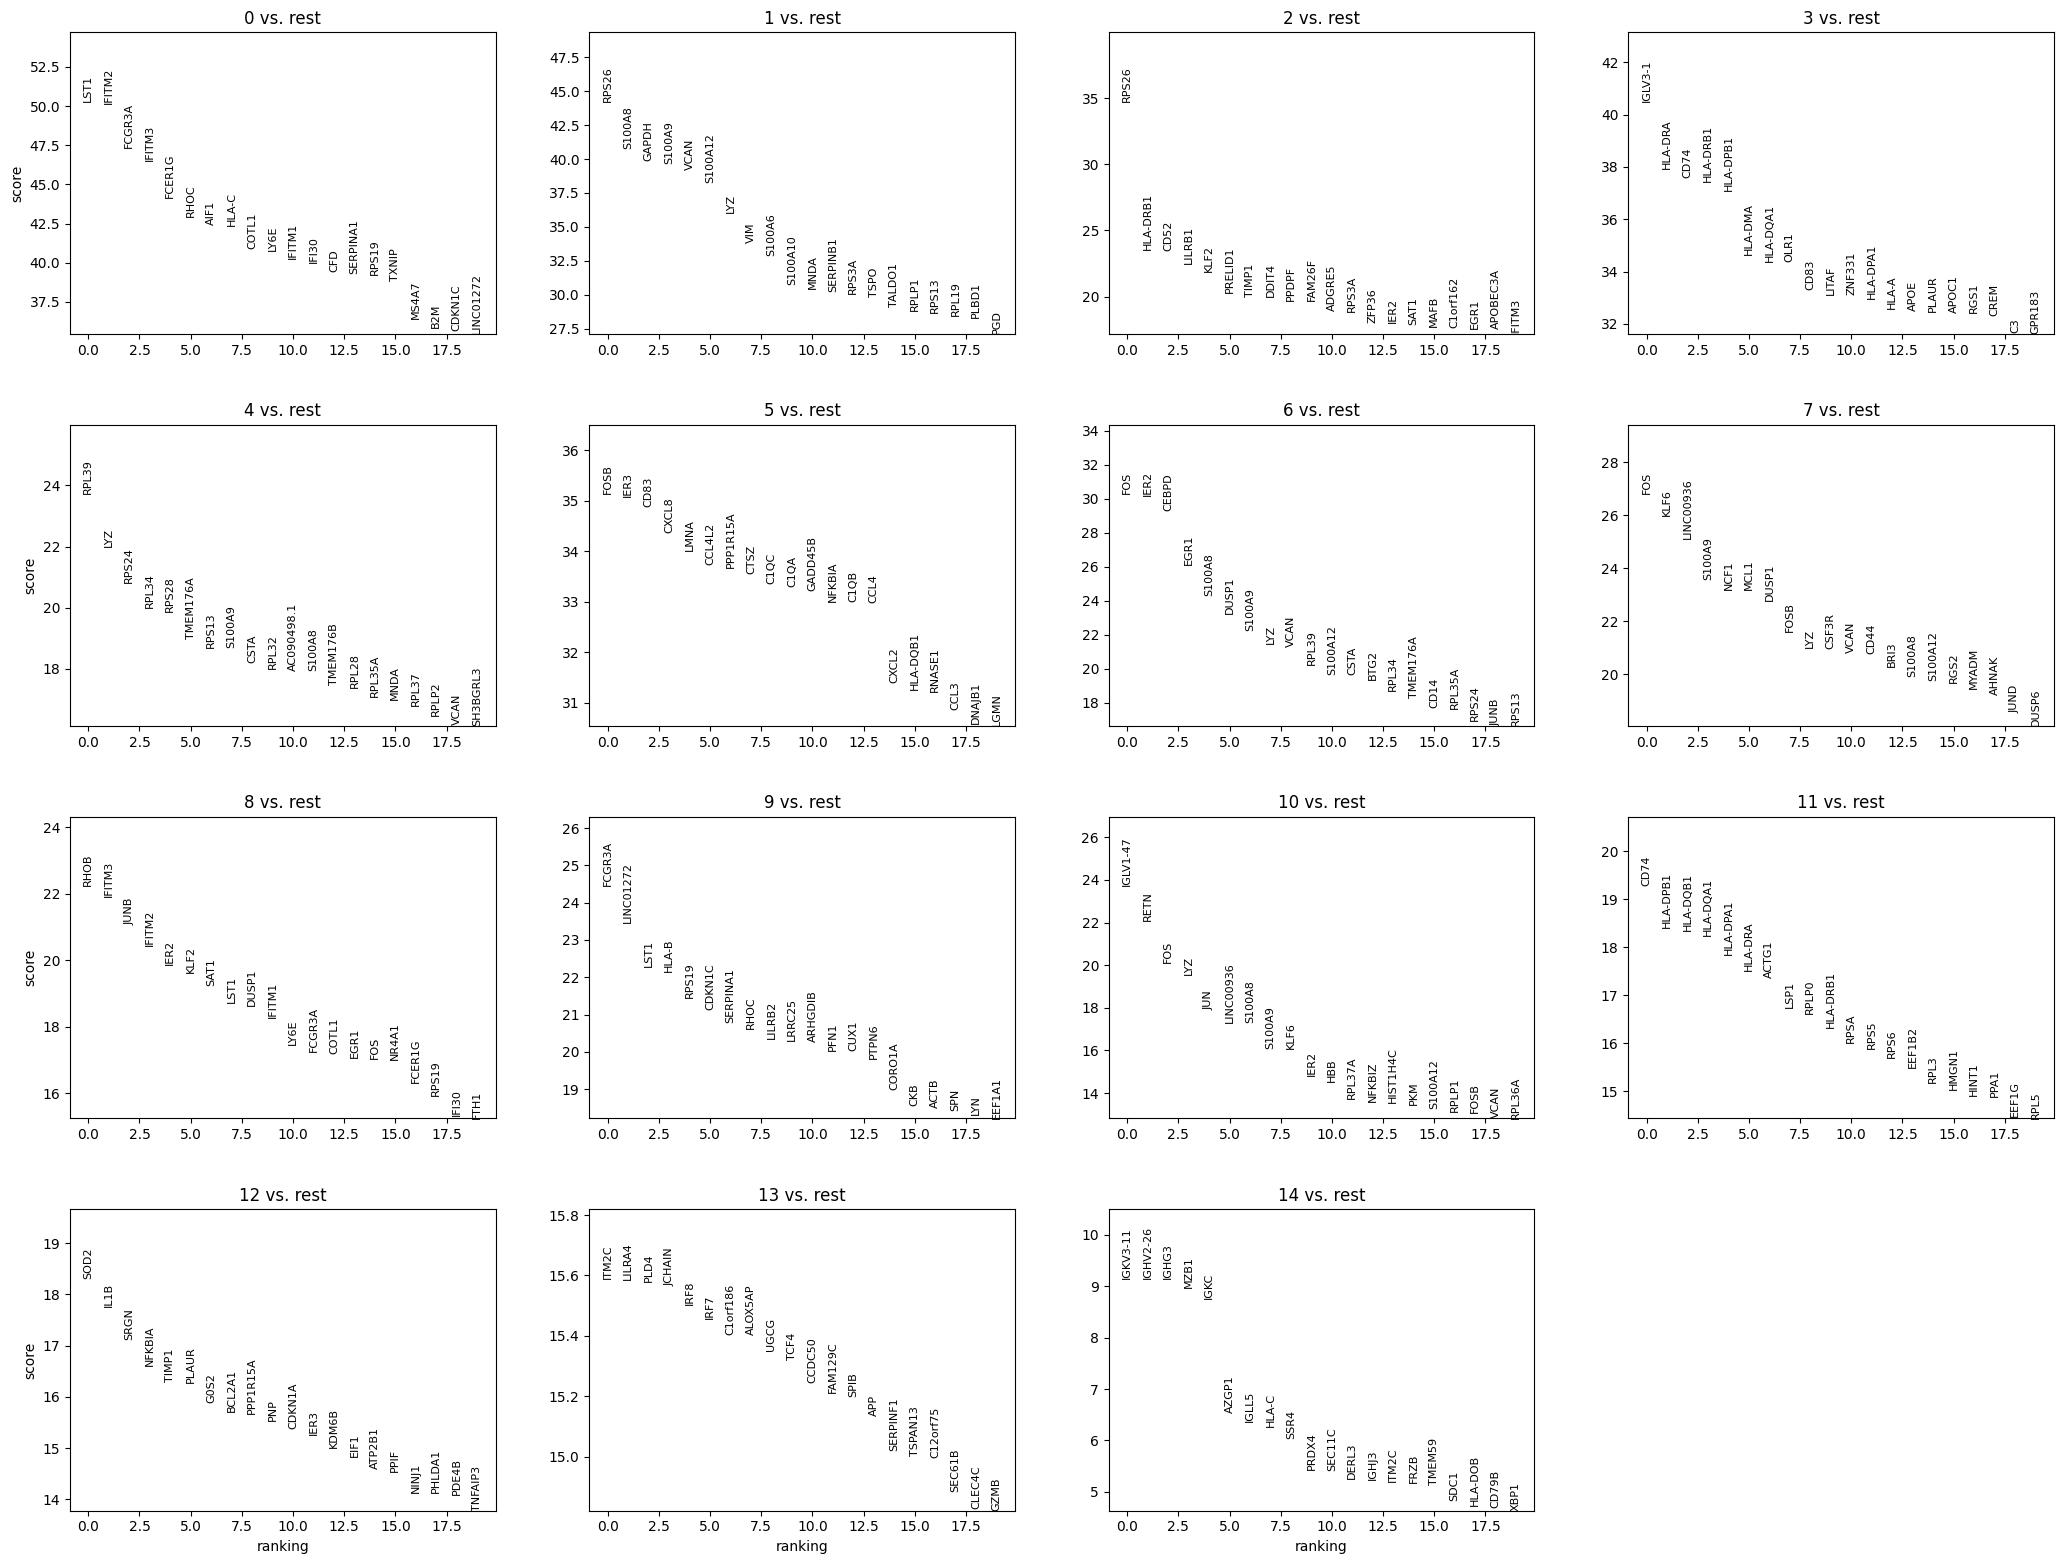

In [24]:
# 클러스터 간 차별 발현 유전자(DEG) 분석 (Wilcoxon rank-sum test)
sc.tl.rank_genes_groups(adata, groupby='leiden', method='wilcoxon')

# 각 클러스터별 상위 5개 마커 유전자 출력
sc.pl.rank_genes_groups(adata, n_genes=20, sharey=False)

### 2. 마커 유전자 시각화 (Dotplot)

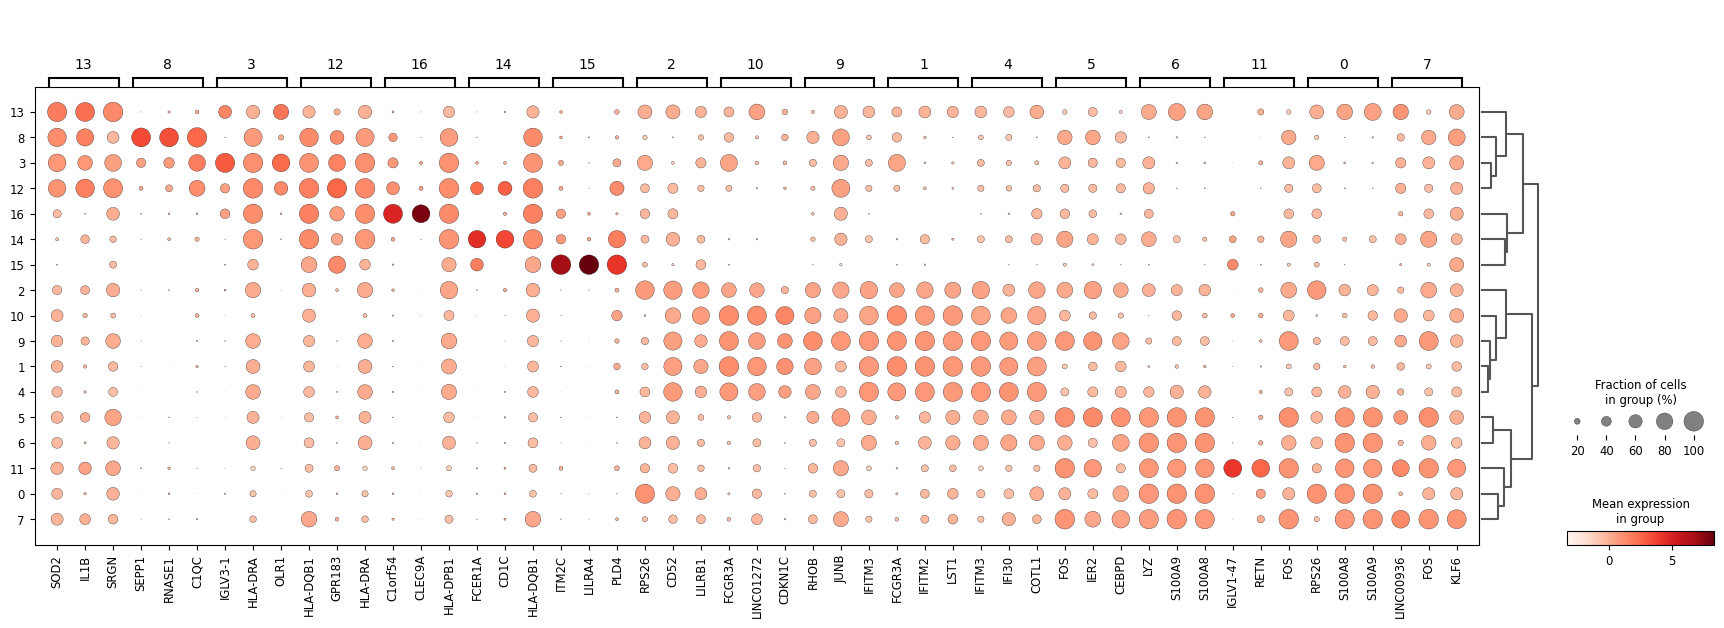

In [ ]:
# 각 클러스터별 상위 3개 마커 유전자들을 요약하여 Dotplot으로 시각화
sc.pl.rank_genes_groups_dotplot(adata, n_genes=3, key='rank_genes_groups', cmap='Reds')

### 3. 세포 유형 어노테이션 및 UMAP 시각화 (Cell Type Annotation)

분석된 마커 유전자를 바탕으로 각 클러스터 번호에 실제 세포 유형 명칭을 매핑합니다.
*(아래 `cell_type_mapping` 딕셔너리의 세포 타입 이름은 마커 유전자 확인 후 연구 목적에 맞게 자유롭게 수정하세요.)*

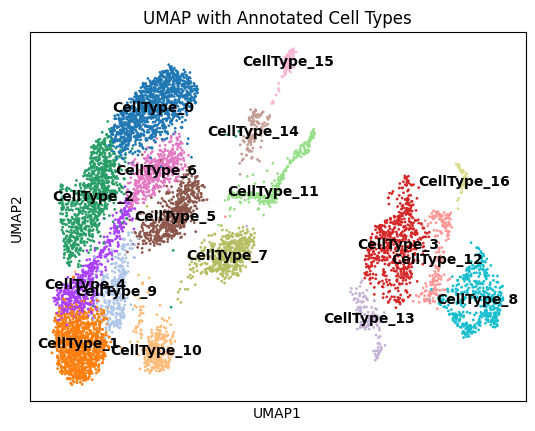

In [ ]:
# 예시 매핑 (사용자 데이터의 마커 유전자를 보고 알맞게 수정해주셔야 합니다)
# 예: 클러스터 '0'이 Macrophage 마커를 많이 발현하면 'Macrophage'로 명명
unique_clusters = adata.obs['leiden'].unique().sort_values()
cell_type_mapping = {cluster: f"CellType_{cluster}" for cluster in unique_clusters}

# 필요 시 실제 알려진 마커에 따라 아래와 같이 직접 이름을 지정합니다:
# cell_type_mapping = {
#     "0": "Macrophage",
#     "1": "Monocyte",
#     "2": "Dendritic Cell",
#     ...
# }

# 데이터에 반영
adata.obs['cell_type'] = adata.obs['leiden'].map(cell_type_mapping)

# 어노테이션된 UMAP 시각화
sc.pl.umap(adata, color='cell_type', legend_loc='on data', title='UMAP with Annotated Cell Types')

### TAM (Tumor-Associated Macrophage) 마커 유전자 발현 시각화

아래 코드를 실행하여 어떤 클러스터가 TAM(대식세포)의 특성을 보이는지 확인합니다.

분석에 사용 가능한 마커: ['CD68', 'CSF1R', 'LYZ', 'CD163', 'MRC1', 'APOE', 'C1QA', 'C1QB', 'SPP1']


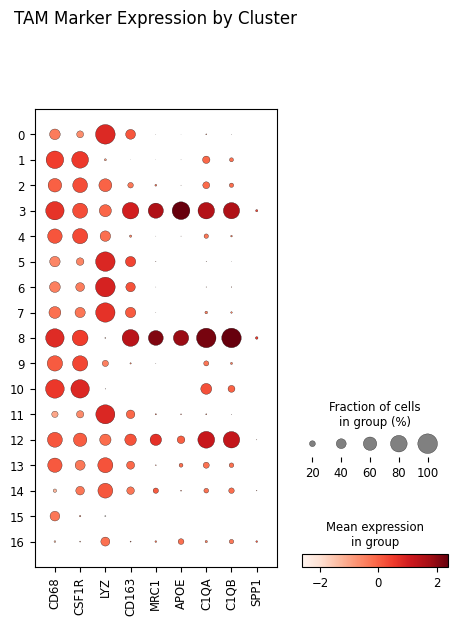

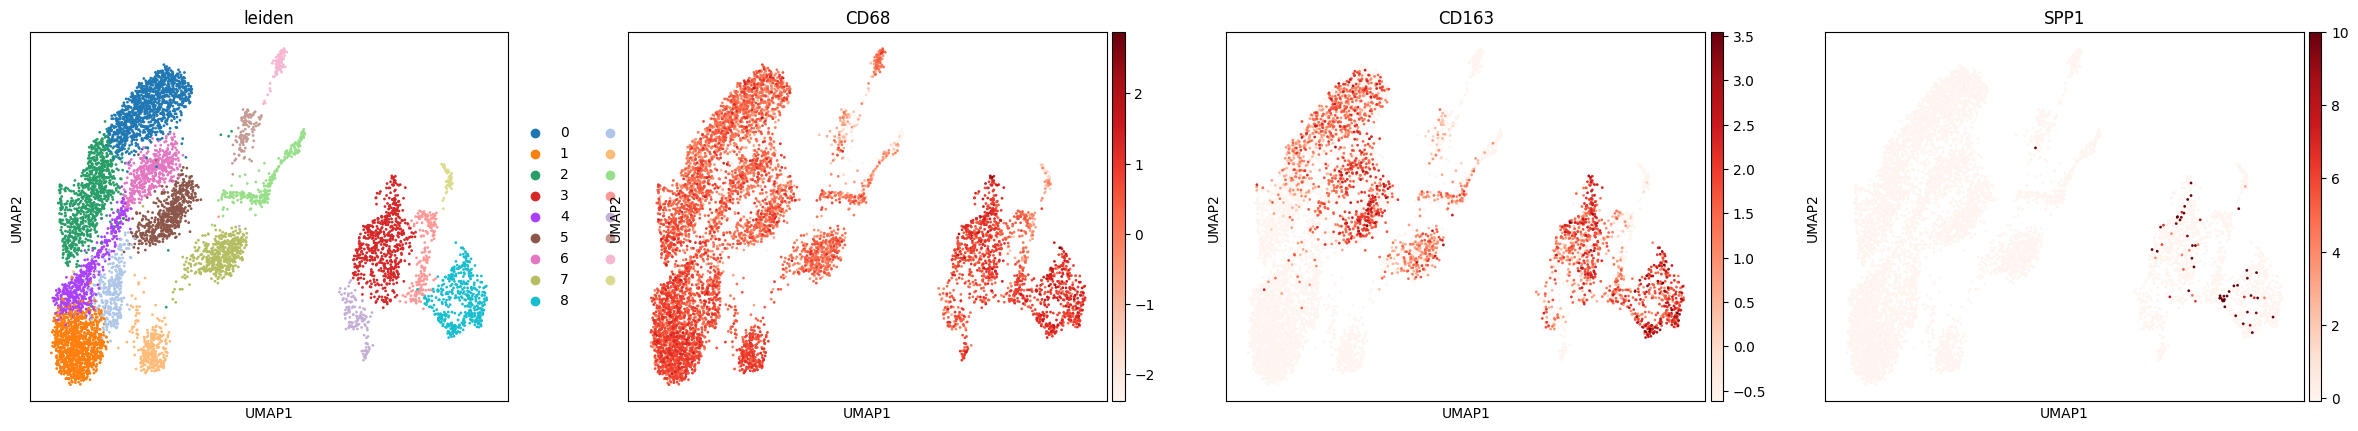

In [ ]:
import scanpy as sc

# 분석할 TAM 대표 마커 유전자 목록 정의 (데이터셋에 존재하는 유전자만 필터링)
tam_markers = ['CD68', 'CSF1R', 'LYZ', 'CD163', 'MRC1', 'APOE', 'C1QA', 'C1QB', 'SPP1']
available_markers = [g for g in tam_markers if g in adata.var_names]

print("분석에 사용 가능한 마커:", available_markers)

# 1. Dotplot을 통해 클러스터별 TAM 마커 발현량 및 발현 비율 확인
sc.pl.dotplot(adata, available_markers, groupby='leiden', cmap='Reds', title='TAM Marker Expression by Cluster')

# 2. UMAP 상에서 주요 마커 발현 시각화
# 특히 CD68(대식세포)과 CD163/MRC1(TAM)의 발현 패턴을 봅니다.
sc.pl.umap(adata, color=['leiden'] + [g for g in ['CD68', 'CD163', 'SPP1'] if g in adata.var_names], cmap='Reds')

In [ ]:
# 간단한 요약 정보 표시 및 유효성 확인
sc.pl.highest_expr_genes(adata, n_top=20, show=True)

NameError: name 'sc' is not defined